<a href="https://colab.research.google.com/github/hafnailmy-bip/DataMining_EvaluasiModel/blob/main/TugasPratikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas 1**

# **Tugas 2**

**2.1 Import Library**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

**2.2 Membuat dataset sintetis**

In [2]:
rng = np.random.default_rng(42)

n = 500

amount = rng.lognormal(
    mean=5.0,
    sigma=1.0,
    size=n
)

hour = rng.integers(0, 24, n)

new_device = rng.binomial(1, 0.25, n)

foreign_ip = rng.binomial(1, 0.12, n)

score = (
    -4.5
    + 0.45 * (amount > 300)
    + 1.1 * new_device
    + 1.5 * foreign_ip
    + 0.7 * (hour < 5)
)

prob = 1 / (1 + np.exp(-score))

isFraud = rng.binomial(1, prob)

df = pd.DataFrame({
    'amount': amount.round(2),
    'hour': hour,
    'new_device': new_device,
    'foreign_ip': foreign_ip,
    'isFraud': isFraud
})

print("Lima Data Pertama:")
print(df.head())

print("\nDistribusi Kelas:")
print(df['isFraud'].value_counts())

Lima Data Pertama:
   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0

Distribusi Kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


**2.3 Membagi dataset dan melatih model**

In [3]:
X = df.drop(columns='isFraud')

y = df['isFraud']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

model = DecisionTreeClassifier(
    max_depth=4,
    class_weight='balanced',
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Jumlah Data Latih:", len(X_train))
print("Jumlah Data Uji:", len(X_test))

Jumlah Data Latih: 350
Jumlah Data Uji: 150


**2.4 Menghitung Confusion Matrix**

In [4]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print("\nNilai TP, TN, FP, FN:")
print("TP =", tp)
print("TN =", tn)
print("FP =", fp)
print("FN =", fn)

Confusion Matrix:
[[113  32]
 [  3   2]]

Nilai TP, TN, FP, FN:
TP = 2
TN = 113
FP = 32
FN = 3


**2.5 Menghitung metrik secara manual**

In [5]:
accuracy = (tp + tn) / (tp + tn + fp + fn)

precision = tp / (tp + fp) if (tp + fp) else 0

recall = tp / (tp + fn) if (tp + fn) else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) else 0
)

print("Hasil Perhitungan Manual:")
print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1-Score :", round(f1, 3))

Hasil Perhitungan Manual:
Accuracy : 0.767
Precision: 0.059
Recall   : 0.4
F1-Score : 0.103


**2.6 Verifikasi menggunakan scikit-learn**

In [6]:
print("Hasil Evaluasi Scikit-Learn:")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1-Score:",
      f1_score(y_test, y_pred, zero_division=0))

Hasil Evaluasi Scikit-Learn:
Accuracy: 0.7666666666666667
Precision: 0.058823529411764705
Recall: 0.4
F1-Score: 0.10256410256410256


**2.7 Visualisasi Confusion Matrix**

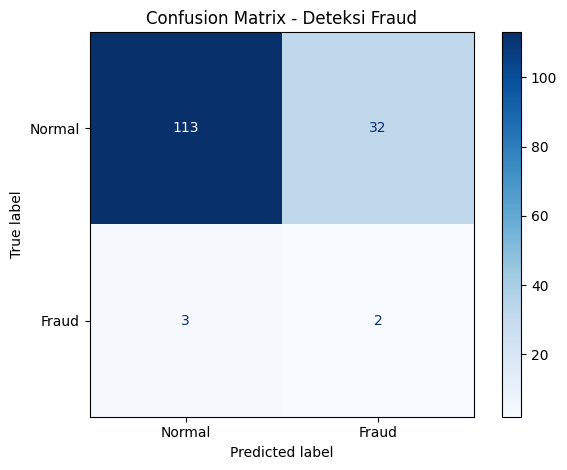

In [7]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Normal', 'Fraud']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - Deteksi Fraud')

plt.tight_layout()

plt.show()

# **Tugas 3**

In [8]:
# Baseline: semua transaksi diprediksi normal

baseline = np.zeros(len(y_test), dtype=int)

from sklearn.metrics import classification_report

print("Baseline Accuracy:")
print(accuracy_score(y_test, baseline))

print("\nClassification Report Baseline:")
print(classification_report(
    y_test,
    baseline,
    labels=[0, 1],
    zero_division=0
))

print("\nClassification Report Decision Tree:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    zero_division=0
))

Baseline Accuracy:
0.9666666666666667

Classification Report Baseline:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150


Classification Report Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



# **Tugas 4**

In [9]:
# Mengambil probabilitas prediksi fraud

y_prob = model.predict_proba(X_test)[
    :, list(model.classes_).index(1)
]

# Menguji empat nilai threshold

for threshold in [0.2, 0.4, 0.5, 0.7]:

    pred = (y_prob >= threshold).astype(int)

    precision = precision_score(
        y_test,
        pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        pred,
        zero_division=0
    )

    print(
        threshold,
        "precision =", round(precision, 3),
        "recall =", round(recall, 3)
    )

0.2 precision = 0.059 recall = 0.4
0.4 precision = 0.059 recall = 0.4
0.5 precision = 0.059 recall = 0.4
0.7 precision = 0.056 recall = 0.2
